# 2.22 · Gradients through physics: finite differences, autodiff and adjoints

**Before this:** [2.06](2-06_matrix_primer.ipynb) (transpose), [2.10](2-10_loss_functions_optimisation.ipynb) (gradient-based optimisation), [2.17](2-17_jax_differentiable.ipynb) (autodiff, Jacobian). Optional notebook.
**You will be able to:** explain why the adjoint is the transpose of the forward model; derive and check an adjoint
for a small ODE (dot-product and Taylor tests); choose between finite differences, forward mode, checkpointed reverse
mode and the continuous adjoint by accuracy, cost and memory; recognise the ways gradients through a solver fail.
**Optional sections:** 3 (discretise or differentiate first), 6b (stiffness).

NUTS, L-BFGS, Gauss-Newton and neural-network training all need the gradient of a loss with respect to the
parameters (2.10). When the forward model is a matrix, the gradient is a matrix product. When it is an ODE or a PDE
solver, there is no matrix to transpose, and the gradient has to be pushed through the solver. This notebook builds
the picture from a linear fault model to a hand-derived adjoint of a small ODE, then to diffrax's options on the real
afterslip solver, then to 40 frictional parameters at once, and ends with the ways it goes wrong.

**Words this notebook defines:** sensitivity, Jacobian, finite differences (FD), tangent-linear model (forward mode,
Jacobian-vector product), adjoint (reverse mode, vector-Jacobian product), dot-product test, adjoint equation,
Lagrange multiplier, discretise-then-differentiate, differentiate-then-discretise, dual consistency, Taylor test,
checkpointing, continuous adjoint (`BacksolveAdjoint`), sensitivity kernel, stiffness, explicit and implicit solvers.

**Problems in this notebook**

| problem | unknowns | data | forward model | linear? |
|---|---|---|---|---|
| antiplane fault slip, as in notebook 2.33 (section 1) | 30 slip patches | 24 stations, σ = 3 mm | screw-dislocation Green's functions | linear |
| two-patch afterslip, small stress changes (sections 2-3) | 2 (log relaxation coefficients) | 3 stations × 20 epochs, σ = 2 mm | linear ODE $\dot{\mathbf y} = \mathbf B(\mathbf m)\,\mathbf y$ | linear in the state, nonlinear in $\mathbf m$ |
| single-patch afterslip (sections 4, 6) | 3 ($\log a\sigma$, $\log v_0$, $\Delta\tau$) | 40 epochs, σ = 2 mm | stiff ODE, $v = 2v_0\sinh(\tau/a\sigma)$ (diffrax) | nonlinear |
| 1-D fault, $a\sigma(z)$ (sections 5-6) | 40 patch values of $\log a\sigma$ (31 can slip) | 30 stations × 40 epochs = 1,200, σ = 2 mm | 80 coupled ODEs (diffrax) | nonlinear |

In [1]:
import os
os.environ["EQX_ON_ERROR"] = "nan"        # a failed solve returns NaN instead of stopping the notebook
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import numpy as np
import matplotlib.pyplot as plt
import bayeskit as bk
from bayeskit import problems as P, samplers as SM, diagnostics as D, plotting as BP, style as S

import time
import jax, jax.numpy as jnp
import diffrax as dfx
from scipy.linalg import expm
from scipy.integrate import solve_ivp
from scipy.optimize import minimize
from bayeskit import afterslip as A

T0 = time.time()
np.set_printoptions(precision=4, suppress=True)


def timeit_ms(fn, *args, repeat=5):
    """Median wall time of a compiled call, in milliseconds (the first call compiles and is not counted)."""
    out = fn(*args); jax.block_until_ready(out)
    ts = []
    for _ in range(repeat):
        t_ = time.perf_counter(); jax.block_until_ready(fn(*args)); ts.append(time.perf_counter() - t_)
    return 1e3 * float(np.median(ts))


def temp_bytes(fn, *args):
    """Temporary memory XLA allocates for one compiled call (bytes)."""
    try:
        return jax.jit(fn).lower(*args).compile().memory_analysis().temp_size_in_bytes
    except Exception:
        return np.nan

## 1. The adjoint is a transpose you never have to build

**In plain words.** The gradient of a misfit answers: "if I nudge each parameter a little, how much does the misfit
change?". For a linear forward model, it is obtained by taking the data residuals and sending them *backwards*
through the forward model, from data space into model space. That backward map is the transpose of the forward
matrix, and it is called the adjoint. In one line: **an adjoint is a transpose you never have to build.**

**Precisely.** For $\mathbf d = \mathbf G\mathbf m$ and $J(\mathbf m) = \tfrac12(\mathbf G\mathbf m - \mathbf d)^\top
\mathbf C_d^{-1}(\mathbf G\mathbf m - \mathbf d)$,

$$\nabla J = \mathbf G^\top\mathbf C_d^{-1}(\mathbf G\mathbf m - \mathbf d).$$

$\mathbf G$ maps model → data; $\mathbf G^\top$ maps a data residual → model. In autodiff language, applying
$\mathbf G$ to a direction is a Jacobian-vector product (JVP, forward mode) and applying $\mathbf G^\top$ to a residual
is a vector-Jacobian product (VJP, reverse mode). JAX computes the VJP of a forward *function* without ever forming
the matrix. The standard check that a backward code really is the transpose of a forward code is the **dot-product
test**: for any $\delta\mathbf m$ and $\delta\mathbf d$, $\langle\mathbf G\,\delta\mathbf m, \delta\mathbf d\rangle =
\langle\delta\mathbf m, \mathbf G^\top\delta\mathbf d\rangle$.

**Worked example.** The fault of notebook 2.33 (30 patches, 24 stations, σ = 3 mm), with the forward model written as a
function (a sum of patch contributions), not as a stored matrix. At a trial model (half the true slip), the code
computes the gradient three ways: building $\mathbf G$ column by column (30 forward runs) and multiplying by
$\mathbf G^\top$; one VJP of the forward function; and `jax.grad` of the misfit. Then 20 dot-product tests.

In [2]:
N1 = 30
ze1 = np.linspace(0, 30, N1 + 1); zc1 = 0.5 * (ze1[1:] + ze1[:-1])
xs1 = np.array([1, 2, 3, 4, 6, 9, 13, 18, 25, 35, 50, 70.0]); xs1 = np.sort(np.r_[-xs1, xs1])
SIG1 = 3.0
s_true1 = 2.0 * np.exp(-0.5 * ((zc1 - 12.0) / 4.0) ** 2)
z1j, z2j, xj = jnp.asarray(ze1[:-1]), jnp.asarray(ze1[1:]), jnp.asarray(xs1)


def forward_slip(m):
    """Surface displacement (mm) at the 24 stations from slip m (m) on the 30 patches: physics, not a stored matrix."""
    return 1000.0 / jnp.pi * jnp.sum(m[None, :] * (jnp.arctan(z2j[None, :] / xj[:, None]) - jnp.arctan(z1j[None, :] / xj[:, None])), axis=1)


d1 = np.asarray(forward_slip(jnp.asarray(s_true1))) + SIG1 * np.random.default_rng(42).standard_normal(xs1.size)
J1 = lambda m: 0.5 * jnp.sum(((forward_slip(m) - d1) / SIG1) ** 2)
m_trial = jnp.asarray(0.5 * s_true1)

G1 = np.column_stack([np.asarray(forward_slip(jnp.asarray(e))) for e in np.eye(N1)])   # 30 forward runs
res1 = (np.asarray(forward_slip(m_trial)) - d1) / SIG1 ** 2
g_explicit = G1.T @ res1
_, vjp_fn = jax.vjp(forward_slip, m_trial)
g_vjp = np.asarray(vjp_fn(jnp.asarray(res1))[0])
g_grad = np.asarray(jax.grad(J1)(m_trial))
print(f"G built from {N1} forward runs, shape {G1.shape}")
print(f"max |G^T r - VJP(r)|      = {np.abs(g_explicit - g_vjp).max():.2e}   (gradient size {np.abs(g_explicit).max():.2e})")
print(f"max |G^T r - jax.grad J|  = {np.abs(g_explicit - g_grad).max():.2e}")

rng = np.random.default_rng(1)
dot_l, dot_r = [], []
for _ in range(20):
    dm, dd = rng.standard_normal(N1), rng.standard_normal(xs1.size)
    Gdm = np.asarray(jax.jvp(forward_slip, (m_trial,), (jnp.asarray(dm),))[1])          # G dm by forward mode
    GTdd = np.asarray(vjp_fn(jnp.asarray(dd))[0])                                        # G^T dd by reverse mode
    dot_l.append(Gdm @ dd); dot_r.append(dm @ GTdd)
dot_l, dot_r = np.array(dot_l), np.array(dot_r)
print(f"dot-product test, 20 random pairs: max |<G dm, dd> - <dm, G^T dd>| / |<G dm, dd>| = "
      f"{np.max(np.abs(dot_l - dot_r) / np.abs(dot_l)):.2e}")
fwd_j = jax.jit(forward_slip); vjp_j = jax.jit(lambda m, r: jax.vjp(forward_slip, m)[1](r)[0])
t_fwd = timeit_ms(fwd_j, m_trial, repeat=50); t_vjp = timeit_ms(vjp_j, m_trial, jnp.asarray(res1), repeat=50)
print(f"cost: one forward run {t_fwd:.3f} ms, one VJP {t_vjp:.3f} ms (ratio {t_vjp / t_fwd:.1f}); building G needs {N1} forward runs")

G built from 30 forward runs, shape (24, 30)
max |G^T r - VJP(r)|      = 9.09e-13   (gradient size 1.30e+04)
max |G^T r - jax.grad J|  = 9.09e-13
dot-product test, 20 random pairs: max |<G dm, dd> - <dm, G^T dd>| / |<G dm, dd>| = 4.28e-14
cost: one forward run 0.024 ms, one VJP 0.023 ms (ratio 1.0); building G needs 30 forward runs


saved figures/2-22_adjoint_transpose.png


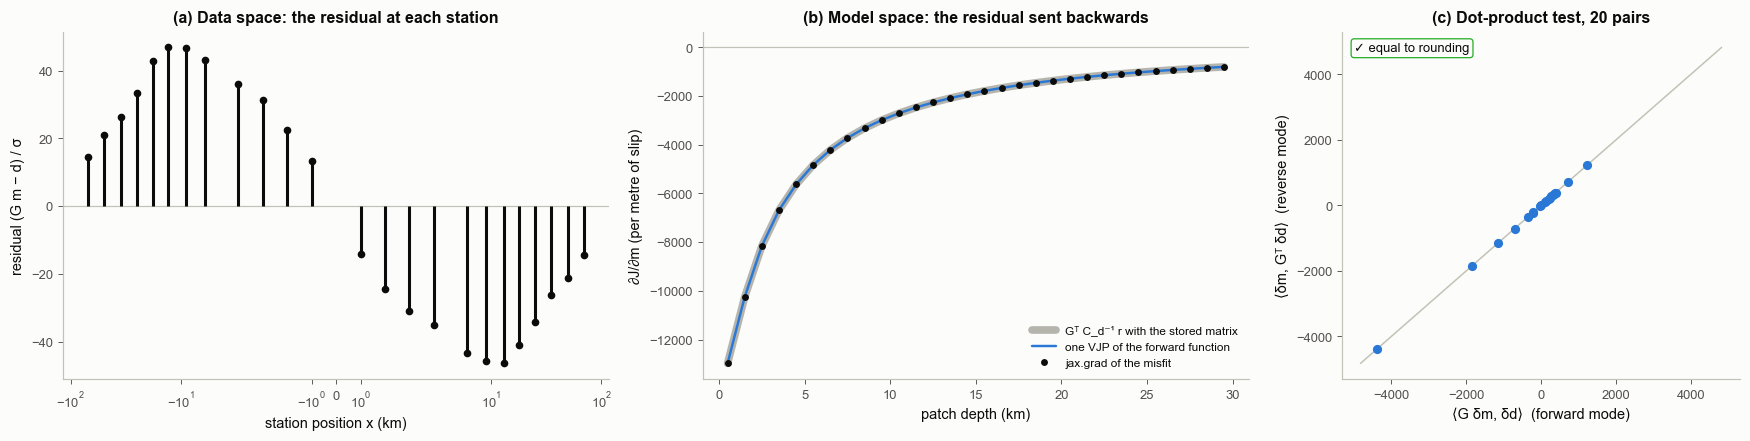

In [3]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4.1), gridspec_kw=dict(width_ratios=[1.1, 1.1, 0.8]))
ax = axs[0]
ax.axhline(0, color=S.AXIS, lw=0.8)
ax.vlines(xs1, 0, res1 * SIG1, color=S.INK, lw=2)
ax.plot(xs1, res1 * SIG1, "o", color=S.INK, ms=4)
ax.set_xscale("symlog", linthresh=5)
ax.set_xlabel("station position x (km)"); ax.set_ylabel("residual (G m − d) / σ")
ax.set_title("(a) Data space: the residual at each station")
ax = axs[1]
ax.plot(zc1, g_explicit, color="#b5b4ad", lw=5, label="Gᵀ C_d⁻¹ r with the stored matrix")
ax.plot(zc1, g_vjp, color=S.BLUE, lw=1.6, label="one VJP of the forward function")
ax.plot(zc1, g_grad, "o", color=S.INK, ms=3.5, label="jax.grad of the misfit")
ax.axhline(0, color=S.AXIS, lw=0.8)
ax.set_xlabel("patch depth (km)"); ax.set_ylabel("∂J/∂m (per metre of slip)")
ax.set_title("(b) Model space: the residual sent backwards")
ax.legend(fontsize=7.8)
ax = axs[2]
lim = 1.1 * np.abs(np.r_[dot_l, dot_r]).max()
ax.plot([-lim, lim], [-lim, lim], color=S.AXIS, lw=1)
ax.plot(dot_l, dot_r, "o", color=S.BLUE, ms=5)
ax.set_xlabel("⟨G δm, δd⟩  (forward mode)"); ax.set_ylabel("⟨δm, Gᵀ δd⟩  (reverse mode)")
ax.set_title("(c) Dot-product test, 20 pairs")
S.badge(ax, "equal to rounding", ok=bool(np.max(np.abs(dot_l - dot_r) / np.abs(dot_l)) < 1e-10), loc="upper left")
fig.tight_layout()
bk.savefig(fig, "2-22_adjoint_transpose")
plt.show()

**How to read it.** (a) The residuals live at the stations. (b) The gradient lives on the fault: each patch collects
the residuals of the stations it influences, weighted by how strongly it influences them (its column of
$\mathbf G$). The three curves coincide (the printed differences are at rounding level). The trial slip is half the
true slip, so adding slip anywhere lowers the misfit and the gradient is negative at every depth. It is largest at the
shallowest patch, not at 12 km where the slip is actually missing, because shallow patches move the stations most per
metre of slip (their columns of $\mathbf G$ are largest). A gradient says which way is downhill for each parameter at
this point; it does not say where the missing slip is (that takes the curvature, 2.10 §4). (c) The dot-product test
passes to rounding: the reverse-mode code is the exact transpose of the forward code.

**The image to keep.** Forward: model → data. Adjoint: residual → model. One adjoint application gives the derivative
with respect to every parameter at once, for about the cost of one forward run (printed ratio), while building
$\mathbf G$ costs one forward run per parameter. For 30 cheap patches that difference is irrelevant; for a PDE with
millions of parameters it is the whole story.

## 2. A hand-derived adjoint: running the misfit backwards in time

Now there is no matrix: the data come out of an ODE. Two fault patches (0-10 and 10-20 km), small stress changes so
that $2v_0\sinh(\tau/a\sigma) \approx c\,\tau$ with $c = 2v_0/a\sigma$, and the coupled system

$$\dot{\boldsymbol\tau} = \mathbf K\,\mathbf C\,\boldsymbol\tau,\qquad \dot{\mathbf s} = \mathbf C\,\boldsymbol\tau,\qquad
\mathbf C = \mathrm{diag}(c_1, c_2),$$

with $\mathbf K$ the stress kernel of `bayeskit.afterslip`. State $\mathbf y = (\boldsymbol\tau, \mathbf s)$, so
$\dot{\mathbf y} = \mathbf B(\mathbf m)\,\mathbf y$ with parameters $\mathbf m = (\log c_1, \log c_2)$. Three surface
stations record $\mathbf h^\top\mathbf y$ at 20 epochs; misfit $J = \tfrac12\sum_i\lVert\mathbf H\mathbf y(t_i) -
\mathbf d_i\rVert^2/\sigma^2$.

**In plain words.** Define $\boldsymbol\lambda(t)$ as "how much the misfit would change if the state were nudged at
time $t$". After the last observation a nudge changes nothing, so $\boldsymbol\lambda = 0$ there. Walking backwards in
time, every observation adds a kick equal to its residual (a nudge just before a datum changes that datum), and between
observations $\boldsymbol\lambda$ is carried back by the transposed dynamics. Once $\boldsymbol\lambda(t)$ is known,
the effect of changing a parameter is the overlap, over time, between $\boldsymbol\lambda$ and the change that
parameter makes to the dynamics.

**Precisely.** With the Lagrangian $\mathcal L = J + \int_0^T\boldsymbol\lambda^\top(\mathbf B\mathbf y - \dot{\mathbf y})\,dt$
(the standard Lagrange-multiplier construction, with the sign of the constraint chosen so that $\boldsymbol\lambda$ is the sensitivity
of $J$ to the state), integrating by parts and choosing
$\boldsymbol\lambda$ to remove every $\partial\mathbf y/\partial\mathbf m$ term gives the **adjoint equation** and the
gradient:

$$\dot{\boldsymbol\lambda} = -\mathbf B^\top\boldsymbol\lambda,\quad \boldsymbol\lambda(T) = 0,\quad
\boldsymbol\lambda(t_i^-) = \boldsymbol\lambda(t_i^+) + \mathbf H^\top\frac{\mathbf H\mathbf y(t_i) - \mathbf d_i}{\sigma^2},
\qquad \frac{\partial J}{\partial m_k} = \int_0^T \boldsymbol\lambda^\top\,\frac{\partial\mathbf B}{\partial m_k}\,\mathbf y\;dt .$$

One forward solve (store $\mathbf y$), one backward solve for $\boldsymbol\lambda$, one integral per parameter.
The cost does not grow with the number of parameters; only the last line does, and it is a cheap quadrature.

**Worked example.** True relaxation rates 4 and 2 per year, gradient evaluated at a wrong guess. The code solves forward,
then backward with the jumps, and compares the gradient with finite differences of the exact solution (matrix
exponential) and with `jax.grad` through `jax.scipy.linalg.expm`.

In [4]:
ze2 = np.array([0.0, 10.0, 20.0])
K2 = A.stress_kernel(ze2)                                     # MPa per m of slip
Hs = A.surface_greens(np.array([5.0, 15.0, 40.0]), ze2)        # m per m of slip at 3 stations
H2 = np.zeros((3, 4)); H2[:, 2:] = Hs
tau0 = np.array([1.0, 0.6])                                   # coseismic stress change (MPa)
y0 = np.r_[tau0, 0.0, 0.0]
m_true2 = np.log(np.array([4.0, 2.0]) / np.abs(np.diag(K2)))   # relaxation rates |K_ii| c_i = 4 and 2 per year
t_obs2 = np.round(np.linspace(0.05, 1.0, 20), 10)
SIG2 = 0.002
print("K (MPa/m):\n", K2)
print("relaxation coefficients c = 2 v0 / a_sigma (m/yr/MPa):", np.exp(m_true2))


def B_of(m):
    c = np.exp(m)
    B = np.zeros((4, 4)); B[:2, :2] = K2 * c[None, :]; B[2:, :2] = np.diag(c)
    return B


def dB_of(m, k):
    c = np.exp(m); E = np.zeros(2); E[k] = c[k]
    B = np.zeros((4, 4)); B[:2, :2] = K2 * E[None, :]; B[2:, :2] = np.diag(E)
    return B


def predict_exact(m, ts=t_obs2):
    B = B_of(m)
    return np.array([H2 @ expm(B * t) @ y0 for t in ts])


d2 = predict_exact(m_true2) + SIG2 * np.random.default_rng(5).standard_normal((t_obs2.size, 3))
J_exact = lambda m: 0.5 * np.sum(((predict_exact(m) - d2) / SIG2) ** 2)
m0_2 = m_true2 + np.array([0.4, -0.3])


def hand_adjoint(m, record=False):
    """Forward solve, then the backward adjoint solve with jumps, then the gradient integral. Tight tolerances."""
    B = B_of(m); dBs = [dB_of(m, 0), dB_of(m, 1)]
    fwd = solve_ivp(lambda t, y: B @ y, (0.0, 1.0), y0, rtol=1e-12, atol=1e-14, dense_output=True)
    resid = (np.array([H2 @ fwd.sol(t) for t in t_obs2]) - d2) / SIG2 ** 2
    rhs = lambda t, z: np.r_[-B.T @ z[:4], [-(z[:4] @ dBk @ fwd.sol(t)) for dBk in dBs]]
    z = np.zeros(6); t_hi = 1.0; rec = []
    for i in range(t_obs2.size - 1, -1, -1):              # walk backwards through the observation times
        if t_hi > t_obs2[i]:
            sol = solve_ivp(rhs, (t_hi, t_obs2[i]), z, rtol=1e-12, atol=1e-14, dense_output=True)
            if record:
                tt = np.linspace(t_hi, t_obs2[i], 30); rec.append((tt, sol.sol(tt)))
            z = sol.y[:, -1]
        z[:4] += H2.T @ resid[i]                           # the kick from datum i
        t_hi = t_obs2[i]
    sol = solve_ivp(rhs, (t_hi, 0.0), z, rtol=1e-12, atol=1e-14, dense_output=True)
    if record:
        tt = np.linspace(t_hi, 0.0, 30); rec.append((tt, sol.sol(tt)))
    grad = sol.y[4:, -1]
    return (grad, fwd, rec) if record else grad


g_hand, fwd2, rec2 = hand_adjoint(m0_2, record=True)
h_fd = 1e-6
g_fd2 = np.array([(J_exact(m0_2 + h_fd * e) - J_exact(m0_2 - h_fd * e)) / (2 * h_fd) for e in np.eye(2)])
K2j, H2j, d2j, y0j = map(jnp.asarray, (K2, H2, d2, y0))


def J_jax(m):
    c = jnp.exp(m)
    B = jnp.zeros((4, 4)).at[:2, :2].set(K2j * c[None, :]).at[2:, :2].set(jnp.diag(c))
    Y = jnp.stack([jax.scipy.linalg.expm(B * t) @ y0j for t in t_obs2])
    return 0.5 * jnp.sum(((Y @ H2j.T - d2j) / SIG2) ** 2)


g_ad2 = np.asarray(jax.grad(J_jax)(jnp.asarray(m0_2)))
print(f"\nmisfit at the guess: {J_exact(m0_2):.2f}")
print("gradient, hand-derived adjoint:          ", g_hand)
print("gradient, central FD of the exact model: ", g_fd2)
print("gradient, jax.grad through expm:         ", g_ad2)
print(f"max relative difference hand vs FD {np.abs(g_hand - g_fd2).max() / np.abs(g_fd2).max():.1e}, "
      f"hand vs jax {np.abs(g_hand - g_ad2).max() / np.abs(g_ad2).max():.1e}")

K (MPa/m):
 [[-1.2732  0.7639]
 [ 0.7639 -1.8553]]
relaxation coefficients c = 2 v0 / a_sigma (m/yr/MPa): [3.1416 1.078 ]



misfit at the guess: 1888.92
gradient, hand-derived adjoint:           [11045.2807  4085.2807]
gradient, central FD of the exact model:  [11045.2807  4085.2807]
gradient, jax.grad through expm:          [11045.2807  4085.2807]
max relative difference hand vs FD 1.9e-10, hand vs jax 4.9e-13


saved figures/2-22_hand_adjoint.png


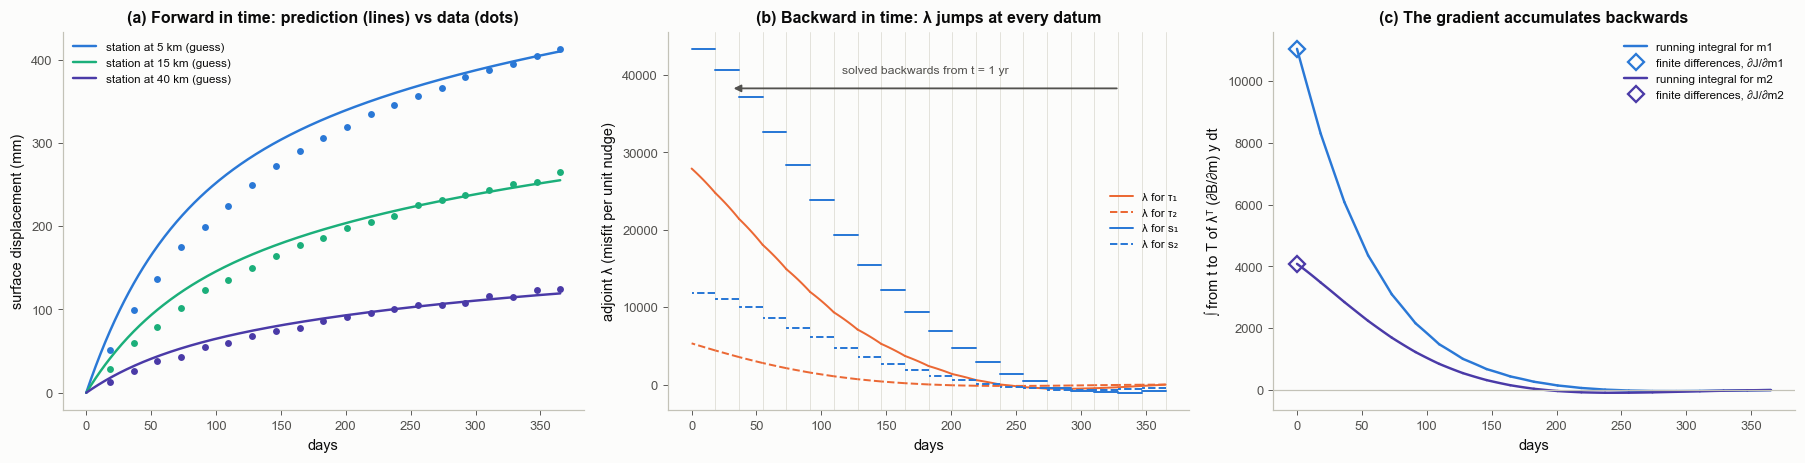

In [5]:
fig, axs = plt.subplots(1, 3, figsize=(16.5, 4.3))
tt = np.linspace(0, 1, 400)
Yd = np.array([fwd2.sol(t) for t in tt])
ax = axs[0]
for j, col in enumerate([S.BLUE, S.AQUA, S.VIOLET]):
    ax.plot(tt * 365.25, 1e3 * Yd @ H2[j], color=col, lw=1.6, label=f"station at {[5, 15, 40][j]} km (guess)")
    ax.plot(t_obs2 * 365.25, 1e3 * d2[:, j], "o", color=col, ms=3.5)
ax.set_xlabel("days"); ax.set_ylabel("surface displacement (mm)")
ax.set_title("(a) Forward in time: prediction (lines) vs data (dots)")
ax.legend(fontsize=7.6)
ax = axs[1]
names = ["λ for τ₁", "λ for τ₂", "λ for s₁", "λ for s₂"]
for k, (col, ls) in enumerate(zip([S.ORANGE, S.ORANGE, S.BLUE, S.BLUE], ["-", "--", "-", "--"])):
    for q, (tq, zq) in enumerate(rec2):
        ax.plot(tq * 365.25, zq[k], color=col, ls=ls, lw=1.3, label=names[k] if q == 0 else None)
for t_ in t_obs2:
    ax.axvline(t_ * 365.25, color=S.GRID, lw=0.6, zorder=0)
ax.annotate("", xy=(30, 0.85), xytext=(330, 0.85), xycoords=("data", "axes fraction"),
            arrowprops=dict(arrowstyle="-|>", color=S.INK2, lw=1.2))
ax.text(180, 0.89, "solved backwards from t = 1 yr", transform=ax.get_xaxis_transform(), ha="center", fontsize=8, color=S.INK2)
ax.set_xlabel("days"); ax.set_ylabel("adjoint λ (misfit per unit nudge)")
ax.set_title("(b) Backward in time: λ jumps at every datum")
ax.legend(fontsize=7.6, loc="center right")
ax = axs[2]
for k, col in enumerate([S.BLUE, S.VIOLET]):
    first = True
    for tq, zq in rec2:
        ax.plot(tq * 365.25, zq[4 + k], color=col, lw=1.6, label=f"running integral for m{k + 1}" if first else None)
        first = False
    ax.plot(0, g_fd2[k], "D", color=col, ms=7, mfc="none", mew=1.5, label=f"finite differences, ∂J/∂m{k + 1}")
ax.axhline(0, color=S.AXIS, lw=0.8)
ax.set_xlabel("days"); ax.set_ylabel("∫ from t to T of λᵀ (∂B/∂m) y dt")
ax.set_title("(c) The gradient accumulates backwards")
ax.legend(fontsize=7.6)
fig.tight_layout()
bk.savefig(fig, "2-22_hand_adjoint")
plt.show()

**How to read it.** (a) The forward run at the wrong guess misses the data. (b) The adjoint is zero after the last
datum and is built from right to left: it jumps at every observation (the kick of that datum's residual) and in
between is carried back by $-\mathbf B^\top$. (c) The running integral starts at zero at $t = 1$ yr and accumulates
as the backward solve proceeds; its value at $t = 0$ is the gradient, and it lands on the finite-difference values
(diamonds; the printed relative differences are tiny).

**The image to keep.** The adjoint recipe in words: run forward; measure the mismatch at the stations; inject that
mismatch as a source at the stations; run the physics backward in time; correlate the backward field with the stored
forward field. That correlation is the gradient. Panel (b) is the injected mismatch travelling backwards; panel (c)
is the correlation.

## 3. Discretise then differentiate, or differentiate then discretise?

**In plain words.** A computer never solves the ODE exactly; it takes time steps. You can either (i) write the adjoint
of the continuous equations, as in section 2, and then solve it with some time steps, or (ii) take the time-stepping
code itself and differentiate *it* (what autodiff does). Both approximate the true gradient, but only (ii) is the exact
gradient of the misfit your code actually computes. An optimiser compares misfit values from your code, so a gradient
from (i) can point in a slightly different direction from the one the misfit values follow. If the two disagree,
the "gradient" is not the gradient of the function the optimiser is minimising, and a line search can stall at a
misfit that has nothing to do with the data. When they agree, the discretisation is called **dual consistent**. The
failure is silent: nothing crashes, the fit just stops improving.

**Precisely.** Discretise the two-patch ODE with Crank-Nicolson steps of size $h$:
$\mathbf y_{n+1} = \mathbf M\mathbf y_n$, $\mathbf M = (\mathbf I - \tfrac h2\mathbf B)^{-1}(\mathbf I + \tfrac h2\mathbf B)$,
and call the resulting misfit $J_h$. (ii) The discrete adjoint is `jax.grad` of $J_h$ through the step loop.
(i) The continuous adjoint is section 2's equations solved with the same Crank-Nicolson steps and the gradient
integral by the trapezoid rule. Both are compared with finite differences of $J_h$ (the derivative of what the code
computes) and with the exact gradient (section 2).

A **Taylor test** checks a gradient $\mathbf g$ against the function it claims to differentiate: the remainder
$\lvert J_h(\mathbf m + \epsilon\mathbf p) - J_h(\mathbf m) - \epsilon\,\mathbf g^\top\mathbf p\rvert$ must shrink like
$\epsilon^2$ if $\mathbf g = \nabla J_h$, and only like $\epsilon$ otherwise.

In [6]:
def J_cn(m, h):
    """Misfit of the Crank-Nicolson solution with step h (JAX; autodiff gives the discrete adjoint)."""
    n, every = int(round(1.0 / h)), int(round(0.05 / h))
    c = jnp.exp(m)
    B = jnp.zeros((4, 4)).at[:2, :2].set(K2j * c[None, :]).at[2:, :2].set(jnp.diag(c))
    I = jnp.eye(4)
    M = jnp.linalg.solve(I - h * B / 2, I + h * B / 2)
    _, ys = jax.lax.scan(lambda y, _: (M @ y, M @ y), y0j, None, length=n)
    return 0.5 * jnp.sum(((ys[every - 1::every] @ H2j.T - d2j) / SIG2) ** 2)


def continuous_adjoint_cn(m, h):
    """Section 2's adjoint equations, solved backwards with the same Crank-Nicolson step; trapezoid rule for the integral."""
    n, every = int(round(1.0 / h)), int(round(0.05 / h))
    B = B_of(m); I = np.eye(4)
    M = np.linalg.solve(I - h * B / 2, I + h * B / 2)
    ys = [y0]
    for _ in range(n):
        ys.append(M @ ys[-1])
    ys = np.array(ys)
    dBs = [dB_of(m, 0), dB_of(m, 1)]
    obs = {every * (i + 1): i for i in range(t_obs2.size)}
    kick = lambda j: H2.T @ ((H2 @ ys[j] - d2[obs[j]]) / SIG2 ** 2) if j in obs else 0.0
    lam_right = np.zeros(4) + kick(n)
    grad = np.zeros(2)
    for j in range(n, 0, -1):
        lam_left = M.T @ lam_right                 # Crank-Nicolson for d(lambda)/dt = -B^T lambda, backwards (= M^T)
        for k in range(2):
            grad[k] += 0.5 * h * (lam_right @ dBs[k] @ ys[j] + lam_left @ dBs[k] @ ys[j - 1])
        lam_right = lam_left + kick(j - 1)
    return grad


g_exact2 = g_ad2
hs3 = [0.05, 0.025, 0.0125, 0.00625, 0.003125]
E3 = {"discrete adjoint (autodiff) vs FD of J_h": [], "continuous adjoint vs FD of J_h": [],
      "discrete adjoint vs exact gradient": [], "continuous adjoint vs exact gradient": []}
for h in hs3:
    Jh = jax.jit(lambda m, h=h: J_cn(m, h))
    g_disc = np.asarray(jax.grad(lambda m: J_cn(m, h))(jnp.asarray(m0_2)))
    g_fdh = np.array([(float(Jh(jnp.asarray(m0_2 + 1e-6 * e))) - float(Jh(jnp.asarray(m0_2 - 1e-6 * e)))) / 2e-6 for e in np.eye(2)])
    g_cont = continuous_adjoint_cn(m0_2, h)
    nrm = np.abs(g_fdh).max()
    for key, val in zip(E3, [g_disc - g_fdh, g_cont - g_fdh, g_disc - g_exact2, g_cont - g_exact2]):
        E3[key].append(np.abs(val).max() / nrm)
    print(f"h = {h:.5f} yr: discrete vs FD(J_h) {E3[list(E3)[0]][-1]:.1e}, continuous vs FD(J_h) {E3[list(E3)[1]][-1]:.1e}, "
          f"discrete vs exact {E3[list(E3)[2]][-1]:.1e}, continuous vs exact {E3[list(E3)[3]][-1]:.1e}")

# Taylor test at the coarsest step
h = 0.05
Jh = jax.jit(lambda m: J_cn(m, h))
g_disc = np.asarray(jax.grad(lambda m: J_cn(m, h))(jnp.asarray(m0_2)))
g_cont = continuous_adjoint_cn(m0_2, h)
p_dir = np.array([0.6, 0.8])
eps = np.logspace(-8, -1, 29)
J0h = float(Jh(jnp.asarray(m0_2)))
taylor = {name: np.array([abs(float(Jh(jnp.asarray(m0_2 + e * p_dir))) - J0h - e * g @ p_dir) for e in eps])
          for name, g in [("discrete adjoint", g_disc), ("continuous adjoint", g_cont)]}

# consequence for an optimiser that evaluates J_h but is handed the continuous-adjoint gradient
gJh = jax.jit(jax.grad(lambda m: J_cn(m, h)))
OPT3 = {}
for name, gfun in [("discrete adjoint", lambda m: np.asarray(gJh(jnp.asarray(m)))), ("continuous adjoint", lambda m: continuous_adjoint_cn(m, h))]:
    r_ = minimize(lambda m: (float(Jh(jnp.asarray(m))), gfun(m)), m0_2, jac=True, method="L-BFGS-B",
                  options=dict(gtol=1e-10, ftol=1e-16, maxiter=200))
    OPT3[name] = r_
    print(f"L-BFGS on J_h (h = {h}) with the {name:18s}: stops at m = {r_.x}, J_h = {r_.fun:.9f}, "
          f"true gradient of J_h there {np.asarray(gJh(jnp.asarray(r_.x)))}")
print(f"distance between the two end points: {np.linalg.norm(OPT3['discrete adjoint'].x - OPT3['continuous adjoint'].x):.2e}; "
      f"for scale, the distance from either to the true m: {np.linalg.norm(OPT3['discrete adjoint'].x - m_true2):.2e}")

h = 0.05000 yr: discrete vs FD(J_h) 5.9e-11, continuous vs FD(J_h) 1.5e-02, discrete vs exact 2.3e-02, continuous vs exact 8.1e-03
h = 0.02500 yr: discrete vs FD(J_h) 6.0e-10, continuous vs FD(J_h) 3.8e-03, discrete vs exact 5.9e-03, continuous vs exact 2.1e-03


h = 0.01250 yr: discrete vs FD(J_h) 1.7e-09, continuous vs FD(J_h) 9.6e-04, discrete vs exact 1.5e-03, continuous vs exact 5.2e-04
h = 0.00625 yr: discrete vs FD(J_h) 2.8e-09, continuous vs FD(J_h) 2.4e-04, discrete vs exact 3.7e-04, continuous vs exact 1.3e-04


h = 0.00313 yr: discrete vs FD(J_h) 3.9e-09, continuous vs FD(J_h) 6.0e-05, discrete vs exact 9.2e-05, continuous vs exact 3.3e-05
L-BFGS on J_h (h = 0.05) with the discrete adjoint  : stops at m = [1.1357 0.0759], J_h = 26.413282936, true gradient of J_h there [-0.  0.]
L-BFGS on J_h (h = 0.05) with the continuous adjoint: stops at m = [1.1357 0.0759], J_h = 26.413283082, true gradient of J_h there [-0.1405 -0.0705]
distance between the two end points: 2.07e-06; for scale, the distance from either to the true m: 9.08e-03


saved figures/2-22_dual_consistency.png


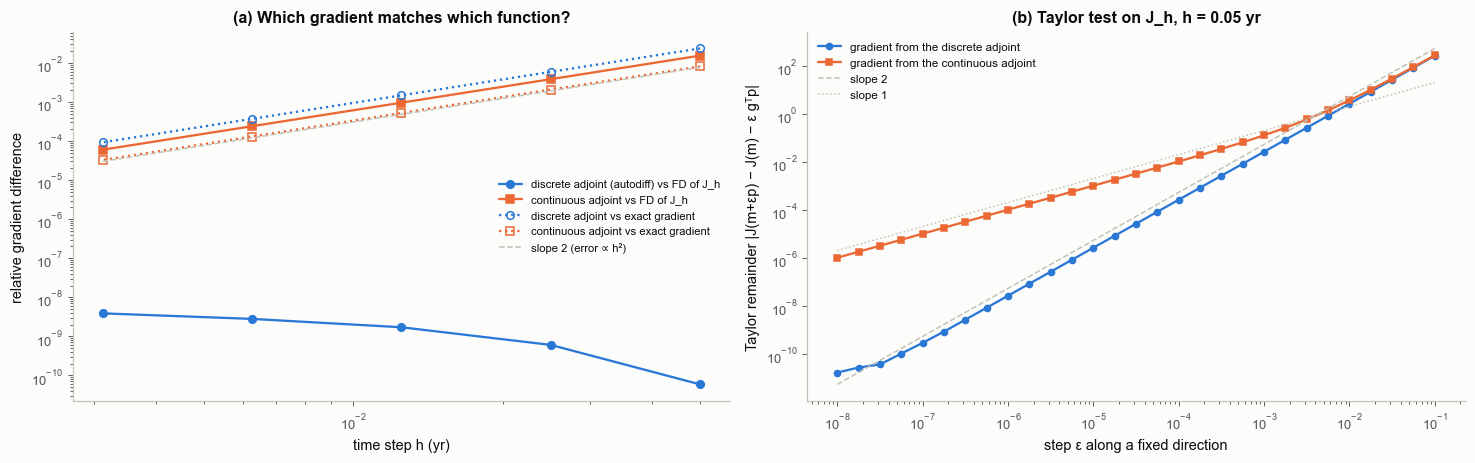

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(13.5, 4.3))
ax = axs[0]
sty = {"discrete adjoint (autodiff) vs FD of J_h": (S.BLUE, "-", "o"), "continuous adjoint vs FD of J_h": (S.ORANGE, "-", "s"),
       "discrete adjoint vs exact gradient": (S.BLUE, ":", "o"), "continuous adjoint vs exact gradient": (S.ORANGE, ":", "s")}
for key, vals in E3.items():
    col, ls, mk = sty[key]
    ax.loglog(hs3, vals, ls=ls, marker=mk, color=col, ms=5, mfc=col if ls == "-" else "none", label=key)
ax.loglog(hs3, 0.5 * E3["continuous adjoint vs FD of J_h"][0] * (np.array(hs3) / hs3[0]) ** 2, color=S.AXIS, lw=1, ls="--", label="slope 2 (error ∝ h²)")
ax.set_xlabel("time step h (yr)"); ax.set_ylabel("relative gradient difference")
ax.set_title("(a) Which gradient matches which function?")
ax.legend(fontsize=7.4, loc="center right")
ax = axs[1]
for (name, rem), col, mk in zip(taylor.items(), [S.BLUE, S.ORANGE], ["o", "s"]):
    ax.loglog(eps, np.maximum(rem, 1e-16), mk + "-", color=col, ms=4, label=f"gradient from the {name}")
ax.loglog(eps, 2 * taylor["discrete adjoint"][-1] * (eps / eps[-1]) ** 2, color=S.AXIS, lw=1, ls="--", label="slope 2")
ax.loglog(eps, 2 * taylor["continuous adjoint"][12] * (eps / eps[12]), color=S.AXIS, lw=1, ls=":", label="slope 1")
ax.set_xlabel("step ε along a fixed direction"); ax.set_ylabel("Taylor remainder |J(m+εp) − J(m) − ε gᵀp|")
ax.set_title(f"(b) Taylor test on J_h, h = {hs3[0]} yr")
ax.legend(fontsize=7.6)
fig.tight_layout()
bk.savefig(fig, "2-22_dual_consistency")
plt.show()

**How to read it.** (a) Solid lines compare each gradient with finite differences of the misfit the code computes
($J_h$). The discrete adjoint (blue) matches it at every step size to the accuracy of the finite differences used to
check it: it *is* the derivative of $J_h$. The continuous adjoint (orange) misses it by an amount that shrinks like $h^2$ (the grey slope). Dotted lines
compare both with the exact gradient of the continuous problem: here both are $O(h^2)$ approximations, and the
continuous adjoint is in fact the closer one (printed above). So neither is "more correct" in general; they answer
different questions, and an optimiser needs the first one. (b) The Taylor test makes the same point without any
reference value: with the discrete adjoint the remainder falls like $\epsilon^2$ until rounding takes over, with the
continuous adjoint it bends to slope 1 at small $\epsilon$, which is the signature of a gradient of a different function.

**How much it matters here.** Very little: the printed L-BFGS runs end at points that differ far less than either
differs from the true parameters, and the continuous-adjoint run stops where the gradient of $J_h$ is small but not
zero. This problem is tiny and well conditioned. The warning matters for large, ill-conditioned PDE inversions,
where the inconsistency can be larger than the remaining true gradient long before the data are fitted.

**The Taylor test is the tool to keep.** It needs only the function and the claimed gradient, so it checks a
hand-written adjoint, a `jax.custom_vjp`, or a gradient handed over by another code.

## 4. The real solver: four ways to get the gradient of the afterslip misfit

Back to the nonlinear single-patch model (stiff ODE, diffrax `Kvaerno5`, adaptive steps). The misfit of 40 GPS epochs
(σ = 2 mm) is differentiated with respect to $\boldsymbol\theta = (\log a\sigma, \log v_0, \Delta\tau)$ four ways:

| method | what it does | solves per gradient |
|---|---|---|
| central finite differences | two perturbed forward solves per parameter | $2N_m$ forward |
| forward mode (`dfx.ForwardMode`, `jax.jacfwd`) | carries one tangent per parameter alongside the forward solve | 1 forward + $N_m$ tangents |
| reverse mode, checkpointed (`dfx.RecursiveCheckpointAdjoint`, diffrax's default) | autodiff of the solver's own steps (discretise, then differentiate), storing a few checkpoints and recomputing between them | 1 forward + 1 backward (+ recomputation) |
| reverse mode, continuous adjoint (`dfx.BacksolveAdjoint`) | solves the adjoint ODE of section 2 backwards with its own adaptive steps (differentiate, then discretise) | 1 forward + 1 backward |

Each is run at three solver tolerances and graded against a reference gradient (checkpointed reverse mode at
rtol = 1e-12). Time is the median wall time of a compiled gradient; memory is the temporary memory XLA allocates
for that compiled call. The local forward function is `afterslip.single_patch_series` with the parameters passed as
solver arguments (which `BacksolveAdjoint` requires); the first printed line checks that they agree.

In [8]:
def _rhs1(t, y, args):
    a_s, v0, k = args
    v = 2.0 * v0 * jnp.sinh(y[0] / a_s)
    return jnp.stack([-k * v, v])


def afterslip_u(theta3, adjoint=dfx.RecursiveCheckpointAdjoint(), rtol=1e-8, solver=None, t_obs=A.T_OBS, k=3.0, g=0.6):
    """Same model as afterslip.single_patch_series; theta3 = (log a_sigma, log v0, dtau)."""
    sol = dfx.diffeqsolve(dfx.ODETerm(_rhs1), solver or dfx.Kvaerno5(), t0=0.0, t1=float(t_obs[-1]), dt0=1e-7,
                          y0=jnp.stack([theta3[2], 0.0 * theta3[2]]), args=(jnp.exp(theta3[0]), jnp.exp(theta3[1]), k),
                          saveat=dfx.SaveAt(ts=jnp.asarray(t_obs)), max_steps=1_000_000, adjoint=adjoint,
                          stepsize_controller=dfx.PIDController(rtol=rtol, atol=rtol * 1e-2))
    return g * sol.ys[:, 1], sol.stats["num_steps"]


TH1 = np.array([np.log(0.5), np.log(0.03), 3.0])
print("max |local forward - afterslip.single_patch_series| =",
      f"{float(jnp.max(jnp.abs(afterslip_u(jnp.asarray(TH1))[0] - A.single_patch_series(jnp.asarray(TH1), A.T_OBS)))):.1e} m")
SIG = 0.002
d1p = np.asarray(afterslip_u(jnp.asarray(TH1))[0]) + SIG * np.random.default_rng(11).standard_normal(A.T_OBS.size)
TH_eval = jnp.asarray(TH1 + np.array([0.05, -0.1, 0.1]))          # gradient evaluated away from the truth
misfit = lambda th, **kw: 0.5 * jnp.sum(((afterslip_u(th, **kw)[0] - d1p) / SIG) ** 2)
g_ref = np.asarray(jax.grad(lambda th: misfit(th, rtol=1e-12))(TH_eval))
print("reference gradient (rtol 1e-12):", g_ref)

METH = {}
for rtol in [1e-3, 1e-5, 1e-8]:
    Lr = jax.jit(lambda th, rtol=rtol: misfit(th, rtol=rtol))
    E = jnp.eye(3)
    fd = jax.jit(lambda th, rtol=rtol: jnp.stack([(Lr(th + 1e-5 * e) - Lr(th - 1e-5 * e)) / 2e-5 for e in E]))
    fm = jax.jit(jax.jacfwd(lambda th, rtol=rtol: misfit(th, rtol=rtol, adjoint=dfx.ForwardMode())))
    ck = jax.jit(jax.grad(lambda th, rtol=rtol: misfit(th, rtol=rtol)))
    bs = jax.jit(jax.grad(lambda th, rtol=rtol: misfit(th, rtol=rtol, adjoint=dfx.BacksolveAdjoint(
        solver=dfx.Kvaerno5(), stepsize_controller=dfx.PIDController(rtol=rtol, atol=rtol * 1e-2)))))
    for name, fn in [("central FD (h = 1e-5)", fd), ("forward mode", fm), ("reverse, checkpointed", ck), ("reverse, continuous adjoint", bs)]:
        g = np.asarray(fn(TH_eval))
        METH[(name, rtol)] = dict(err=np.abs(g - g_ref).max() / np.abs(g_ref).max(), ms=timeit_ms(fn, TH_eval), mem=temp_bytes(fn, TH_eval))
print(f"\n{'method':30s} {'rtol':>6s} {'rel. error':>11s} {'ms':>8s} {'temp memory (kB)':>17s}")
for (name, rtol), v in METH.items():
    print(f"{name:30s} {rtol:6.0e} {v['err']:11.1e} {v['ms']:8.2f} {v['mem'] / 1e3:17.1f}")

# finite differences: error against the step h, at a loose and a tight tolerance
hs4 = np.logspace(-12, -1, 23)
FDU = {}
for rtol in [1e-4, 1e-8]:
    Lr = jax.jit(lambda th, rtol=rtol: misfit(th, rtol=rtol))
    errs = []
    for hh in hs4:
        g = np.array([(float(Lr(TH_eval + hh * e)) - float(Lr(TH_eval - hh * e))) / (2 * hh) for e in np.eye(3)])
        errs.append(np.abs(g - g_ref).max() / np.abs(g_ref).max())
    ad = np.asarray(jax.grad(lambda th, rtol=rtol: misfit(th, rtol=rtol))(TH_eval))
    FDU[rtol] = (np.array(errs), np.abs(ad - g_ref).max() / np.abs(g_ref).max())
    print(f"rtol {rtol:.0e}: best central FD error {min(errs):.1e} at h = {hs4[np.argmin(errs)]:.0e}; autodiff error {FDU[rtol][1]:.1e}")

max |local forward - afterslip.single_patch_series| = 8.5e-15 m


reference gradient (rtol 1e-12): [ 27975.1271  -6151.8386 -11722.3176]



method                           rtol  rel. error       ms  temp memory (kB)
central FD (h = 1e-5)           1e-03     2.5e-04     2.36              19.2
forward mode                    1e-03     2.8e-04     0.78               8.4
reverse, checkpointed           1e-03     2.8e-04     2.59             240.1
reverse, continuous adjoint     1e-03     3.3e-04     3.77              13.0
central FD (h = 1e-5)           1e-05     3.8e-06     5.08              19.2
forward mode                    1e-05     7.2e-06     1.67               8.4
reverse, checkpointed           1e-05     7.2e-06     5.44             240.1
reverse, continuous adjoint     1e-05     8.6e-06     4.36              13.0
central FD (h = 1e-5)           1e-08     1.2e-07    18.24              19.2
forward mode                    1e-08     3.1e-08     6.14               8.4
reverse, checkpointed           1e-08     3.1e-08    20.76             240.1
reverse, continuous adjoint     1e-08     3.7e-08    12.09              13.

rtol 1e-04: best central FD error 1.5e-05 at h = 1e-10; autodiff error 4.2e-05


rtol 1e-08: best central FD error 2.3e-08 at h = 1e-04; autodiff error 3.1e-08


saved figures/2-22_single_patch_methods.png


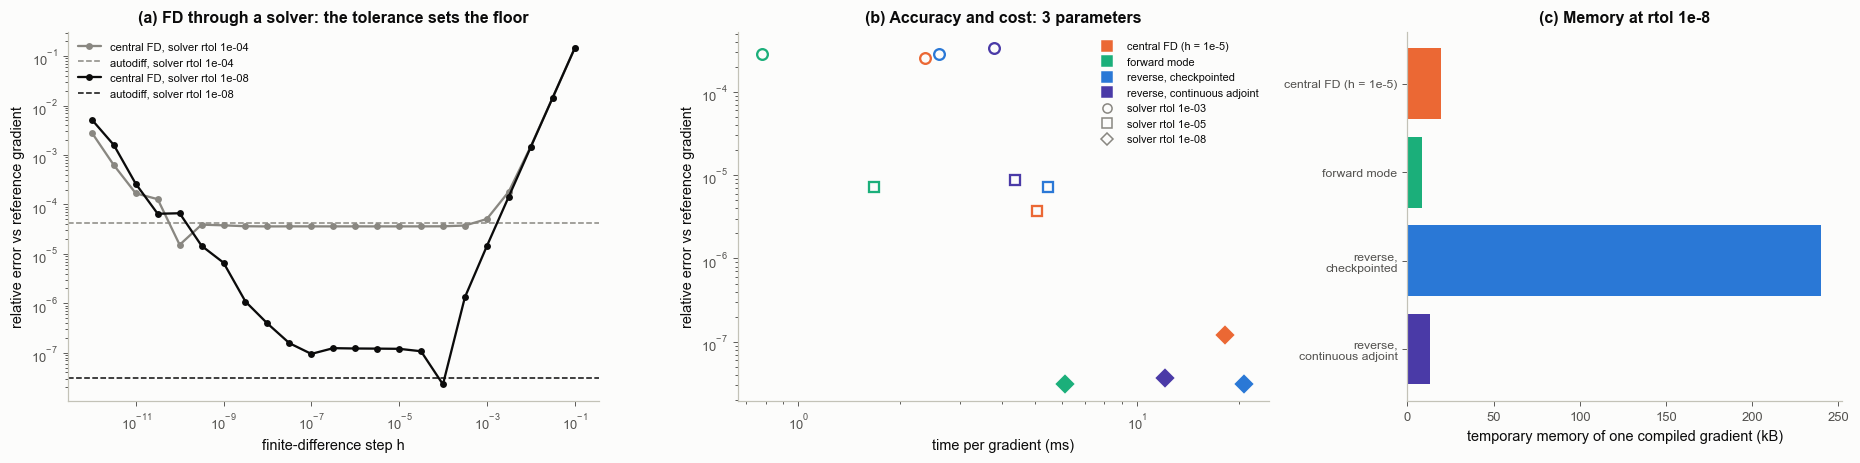

In [9]:
MCOL = {"central FD (h = 1e-5)": S.ORANGE, "forward mode": S.AQUA, "reverse, checkpointed": S.BLUE, "reverse, continuous adjoint": S.VIOLET}
MMK = {1e-3: "o", 1e-5: "s", 1e-8: "D"}
fig, axs = plt.subplots(1, 3, figsize=(17, 4.3), gridspec_kw=dict(width_ratios=[1.1, 1.1, 0.9]))
ax = axs[0]
for rtol, col in [(1e-4, S.MUTED), (1e-8, S.INK)]:
    errs, ad = FDU[rtol]
    ax.loglog(hs4, errs, "o-", color=col, ms=3.5, label=f"central FD, solver rtol {rtol:.0e}")
    ax.axhline(ad, color=col, ls="--", lw=1, label=f"autodiff, solver rtol {rtol:.0e}")
ax.set_xlabel("finite-difference step h"); ax.set_ylabel("relative error vs reference gradient")
ax.set_title("(a) FD through a solver: the tolerance sets the floor")
ax.legend(fontsize=7.4, loc="upper left")
ax = axs[1]
for (name, rtol), v in METH.items():
    ax.loglog(v["ms"], v["err"], MMK[rtol], color=MCOL[name], ms=7, mfc=MCOL[name] if rtol == 1e-8 else "none", mew=1.5)
for name, col in MCOL.items():
    ax.plot([], [], "s", color=col, label=name)
for rtol, mk in MMK.items():
    ax.plot([], [], mk, color=S.MUTED, mfc="none", label=f"solver rtol {rtol:.0e}")
ax.set_xlabel("time per gradient (ms)"); ax.set_ylabel("relative error vs reference gradient")
ax.set_title("(b) Accuracy and cost: 3 parameters")
ax.legend(fontsize=7.2, loc="upper right")
ax = axs[2]
names = list(MCOL)
mems = [METH[(n, 1e-8)]["mem"] / 1e3 for n in names]
ax.barh(range(4), mems, color=[MCOL[n] for n in names])
ax.set_yticks(range(4)); ax.set_yticklabels([n.replace(", ", ",\n") for n in names], fontsize=8)
ax.invert_yaxis()
ax.set_xlabel("temporary memory of one compiled gradient (kB)")
ax.set_title("(c) Memory at rtol 1e-8")
fig.tight_layout()
bk.savefig(fig, "2-22_single_patch_methods")
plt.show()

**How to read it.** (a) Through an adaptive solver, finite differences are only as accurate as the solver: at a loose
tolerance the error is flat across many orders of magnitude of $h$ at about the level the autodiff gradient reaches
with the same tolerance (dashed). The step $h$ no longer matters much; the tolerance does. (b) Every method's error
tracks the solver tolerance (the three marker shapes), not the method: all four approximate the gradient of the true,
continuous problem to roughly the tolerance. With three parameters, forward mode is the fastest (three tangents ride
along one solve) and the methods differ by small factors. (c) Of the two reverse modes, the continuous adjoint needs
far less memory, because it does not store the forward steps: it re-solves the forward ODE backwards alongside the
adjoint. Checkpointing stores a few states and recomputes the rest, trading computation for memory. Forward mode and finite
differences need little memory too, since they carry everything forwards; their price is paid in the number of
parameters (next section).

**The image to keep.** For a handful of parameters every method works, and the solver tolerance sets the accuracy.
The differences that decide the choice appear when the number of parameters grows (next section) and when memory is
limited (long PDE simulations).

## 5. Forty parameters: the 1-D fault and the sensitivity kernel

**In plain words.** Now the unknown is a whole depth profile $\log a\sigma(z)$ on the 40 patches of the 1-D fault
(31 of them can slip; the others had a coseismic stress drop and are pinned, as described in the module docstring).
The data are 30 GPS stations × 40 epochs. The gradient of the misfit with respect to the profile tells, patch by
patch, which way to change $a\sigma$ to fit better: a sensitivity kernel, the 1-D cousin of the banana-doughnut
kernels of seismic tomography.

**Precisely.** Cost of one gradient with $p$ parameters: finite differences $p+1$ forward solves, forward mode
$p$ tangent solves (carried together), reverse mode one forward plus one backward solve whatever $p$ is. To measure
the scaling with $p$ on the same physics, the 40-patch profile is parameterised by $p$ piecewise-constant blocks
($p$ = 1, 3, 10, 40). Then, with reverse-mode gradients, L-BFGS finds the MAP profile under the module's
Gaussian-process prior (Matérn, ℓ = 8 km, ν = 1.5, sd 0.5 around log 0.8 MPa; 2.12), written in whitened coordinates
$\log a\sigma = \boldsymbol\mu + \mathbf L\mathbf u$ ($\mathbf L$ the Cholesky factor of the prior covariance;
whitening and Cholesky are drawn in 2.06, section 5) so that the prior term is $\tfrac12\lVert\mathbf u\rVert^2$
(2.10 §5: precondition), and kept within ±3 prior standard deviations in those coordinates. One technical detail:
the argument of sinh is clipped at ±50 inside the solver. On every trajectory this never binds (the printed
check: clipped and unclipped forward runs are identical), but without it the gradient can be NaN; section 6a
shows why.

In [10]:
la_set, slip_set, surf_set, setup = A.training_set_fault(1500, seed=0)
NP = 40
K_f, G_f = jnp.asarray(setup["K"]), jnp.asarray(setup["G"])
dtau_f, free_f = jnp.asarray(setup["dtau"]), jnp.asarray(setup["free"], dtype=jnp.float64)
zc_f = setup["zc"]


def make_rhs(clip):
    def _rhs_f(t, y, args):
        a_s, free = args
        x = y[:NP] / a_s
        if clip is not None:
            x = jnp.clip(x, -clip, clip)          # never reached on a real trajectory; see section 6a
        v = free * 2.0 * 0.03 * jnp.sinh(x)
        return jnp.concatenate([K_f @ v, v])
    return _rhs_f


RHS_CLIP, RHS_RAW = make_rhs(50.0), make_rhs(None)


def fault_surface(log_asig, dtau=dtau_f, free=free_f, adjoint=dfx.RecursiveCheckpointAdjoint(), rtol=1e-5, solver=None,
                  clip=True):
    """afterslip.fault_surface with the mask and stress change passed as arguments (sections 5-6)."""
    sol = dfx.diffeqsolve(dfx.ODETerm(RHS_CLIP if clip else RHS_RAW), solver or dfx.Kvaerno5(), t0=0.0, t1=1.0, dt0=1e-8,
                          y0=jnp.concatenate([dtau, jnp.zeros(NP)]), args=(jnp.exp(log_asig), free),
                          saveat=dfx.SaveAt(ts=jnp.asarray(A.T_OBS)), max_steps=400_000, adjoint=adjoint,
                          stepsize_controller=dfx.PIDController(rtol=rtol, atol=rtol * 1e-2))
    return sol.ys[:, NP:] @ G_f.T, sol.stats["num_steps"]


TRUE_F = la_set[3]
print("max |local fault forward - cached training run| =",
      f"{float(jnp.max(jnp.abs(fault_surface(jnp.asarray(TRUE_F))[0] - surf_set[3]))) * 1e3:.1e} mm")
print("max |clipped - unclipped forward| over 20 cached profiles =",
      f"{max(float(jnp.max(jnp.abs(fault_surface(jnp.asarray(la_set[i]))[0] - fault_surface(jnp.asarray(la_set[i]), clip=False)[0]))) for i in range(20)):.1e} m")
d_f = np.asarray(fault_surface(jnp.asarray(TRUE_F))[0]) + SIG * np.random.default_rng(1).standard_normal((A.T_OBS.size, 30))
MU_F = np.log(0.8)
C_f = A.matern_cov(zc_f, 8.0, 1.5, 0.5) + 1e-10 * np.eye(NP)
L_f = np.linalg.cholesky(C_f)
misfit_f = lambda la, **kw: 0.5 * jnp.sum(((fault_surface(la, **kw)[0] - d_f) / SIG) ** 2)
la0 = jnp.full(NP, MU_F)
grad_f = jax.jit(jax.grad(misfit_f))
kernel = np.asarray(grad_f(la0))
Lf_jit = jax.jit(misfit_f)
for j in [5, 15, 25]:
    e = np.zeros(NP); e[j] = 1e-5
    fdj = (float(Lf_jit(la0 + e)) - float(Lf_jit(la0 - e))) / 2e-5
    print(f"patch {j:2d} ({zc_f[j]:4.1f} km): adjoint {kernel[j]:12.3f}   central FD {fdj:12.3f}")
print(f"gradient on the {int((~setup['free']).sum())} pinned patches: max |dJ/dlog a_sigma| = {np.abs(kernel[~setup['free']]).max():.1e}")

# cost against the number of parameters
def block_map(p):
    edges = np.linspace(0, NP, p + 1).astype(int); M = np.zeros((NP, p))
    for j in range(p):
        M[edges[j]:edges[j + 1], j] = 1
    return jnp.asarray(M)


COST = {"finite differences (p + 1 forward solves)": [], "forward mode (jacfwd)": [], "reverse, checkpointed": [],
        "reverse, continuous adjoint": [], "one forward solve": []}
PS = [1, 3, 10, 40]
for p in PS:
    Mb = block_map(p); q0 = jnp.zeros(p)
    Lq = jax.jit(lambda q, Mb=Mb: misfit_f(MU_F + Mb @ q))
    fd_q = lambda q, Lq=Lq: [Lq(q + 1e-5 * e) for e in jnp.eye(p)] + [Lq(q)]
    COST["finite differences (p + 1 forward solves)"].append(timeit_ms(fd_q, q0, repeat=2))
    COST["forward mode (jacfwd)"].append(timeit_ms(jax.jit(jax.jacfwd(lambda q, Mb=Mb: misfit_f(MU_F + Mb @ q, adjoint=dfx.ForwardMode()))), q0, repeat=2))
    COST["reverse, checkpointed"].append(timeit_ms(jax.jit(jax.grad(lambda q, Mb=Mb: misfit_f(MU_F + Mb @ q))), q0, repeat=2))
    COST["reverse, continuous adjoint"].append(timeit_ms(jax.jit(jax.grad(lambda q, Mb=Mb: misfit_f(MU_F + Mb @ q, adjoint=dfx.BacksolveAdjoint(
        solver=dfx.Kvaerno5(), stepsize_controller=dfx.PIDController(rtol=1e-5, atol=1e-7))))), q0, repeat=2))
    COST["one forward solve"].append(timeit_ms(Lq, q0, repeat=2))
    print(f"p = {p:2d}: " + ", ".join(f"{k.split(' (')[0]} {v[-1]:.0f} ms" for k, v in COST.items()))

max |local fault forward - cached training run| = 5.3e-08 mm


max |clipped - unclipped forward| over 20 cached profiles = 0.0e+00 m


patch  5 ( 5.5 km): adjoint        0.000   central FD        0.000
patch 15 (15.5 km): adjoint    -4520.442   central FD    -4520.380


patch 25 (25.5 km): adjoint      -48.356   central FD      -48.356
gradient on the 9 pinned patches: max |dJ/dlog a_sigma| = 0.0e+00


p =  1: finite differences 155 ms, forward mode 180 ms, reverse, checkpointed 345 ms, reverse, continuous adjoint 750 ms, one forward solve 78 ms


p =  3: finite differences 310 ms, forward mode 192 ms, reverse, checkpointed 344 ms, reverse, continuous adjoint 753 ms, one forward solve 78 ms


p = 10: finite differences 854 ms, forward mode 196 ms, reverse, checkpointed 340 ms, reverse, continuous adjoint 756 ms, one forward solve 78 ms


p = 40: finite differences 3174 ms, forward mode 244 ms, reverse, checkpointed 341 ms, reverse, continuous adjoint 754 ms, one forward solve 78 ms


In [11]:
# MAP profile with reverse-mode gradients and L-BFGS, in whitened coordinates
Lfj = jnp.asarray(L_f)
obj_f = lambda u: misfit_f(MU_F + Lfj @ u) + 0.5 * jnp.sum(u ** 2)
vg_f = jax.jit(jax.value_and_grad(obj_f))
n_eval, n_fail, g_last = [0], [0], [np.zeros(NP)]


def fun_f(u):
    n_eval[0] += 1
    v, g = vg_f(jnp.asarray(u))
    v, g = float(v), np.asarray(g)
    if not (np.isfinite(v) and np.all(np.isfinite(g))):       # a failed solve: report a bad value, keep the last gradient
        n_fail[0] += 1
        return 1e12, g_last[0]
    g_last[0] = g
    return v, g


t_ = time.time()
res_f = minimize(fun_f, np.zeros(NP), jac=True, method="L-BFGS-B", bounds=[(-3, 3)] * NP, options=dict(maxiter=150))
t_map = time.time() - t_
la_map = MU_F + L_f @ res_f.x
chi2_map = 2 * float(misfit_f(jnp.asarray(la_map)))
chi2_true = 2 * float(misfit_f(jnp.asarray(TRUE_F)))
fr = setup["free"]
print(f"L-BFGS: {res_f.nit} iterations, {n_eval[0]} misfit+gradient evaluations ({n_fail[0]} failed), {t_map:.0f} s; "
      f"message: {res_f.message}")
print(f"chi^2 of the MAP {chi2_map:.0f}, of the true profile {chi2_true:.0f}, number of data {d_f.size}")
print(f"RMS(log a_sigma MAP - true) on the free patches: {np.sqrt(np.mean((la_map - TRUE_F)[fr] ** 2)):.3f}  (prior sd 0.5)")
print(f"same computation with central finite differences would need {2 * NP} forward solves per gradient, "
      f"i.e. {n_eval[0] * 2 * NP} solves instead of {n_eval[0]} forward + {n_eval[0]} backward")

L-BFGS: 65 iterations, 78 misfit+gradient evaluations (0 failed), 48 s; message: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
chi^2 of the MAP 1183, of the true profile 1190, number of data 1200
RMS(log a_sigma MAP - true) on the free patches: 0.252  (prior sd 0.5)
same computation with central finite differences would need 80 forward solves per gradient, i.e. 6240 solves instead of 78 forward + 78 backward


saved figures/2-22_fault_gradients.png


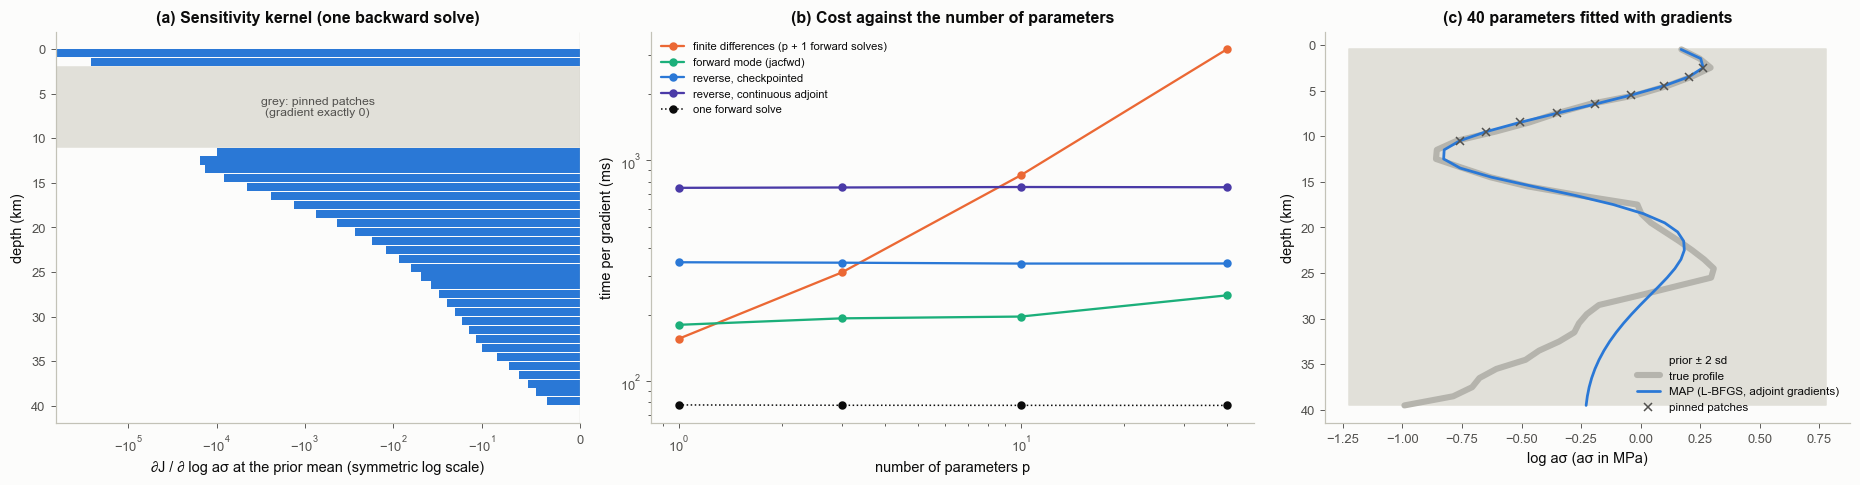

In [12]:
fig, axs = plt.subplots(1, 3, figsize=(17, 4.5), gridspec_kw=dict(width_ratios=[1, 1.15, 1]))
ax = axs[0]
ax.barh(zc_f, kernel, height=0.9, color=np.where(kernel < 0, S.BLUE, S.ORANGE))
for j in np.where(~fr)[0]:
    ax.axhspan(zc_f[j] - 0.5, zc_f[j] + 0.5, color=S.GRID, zorder=0)
ax.axvline(0, color=S.AXIS, lw=0.8)
ax.set_xscale("symlog", linthresh=10)
ax.invert_yaxis()
ax.set_xlabel("∂J / ∂ log aσ at the prior mean (symmetric log scale)"); ax.set_ylabel("depth (km)")
ax.set_title("(a) Sensitivity kernel (one backward solve)")
ax.text(0.5, 6.5, "grey: pinned patches\n(gradient exactly 0)", transform=ax.get_yaxis_transform(), ha="center", va="center",
        fontsize=8, color=S.INK2)
ax = axs[1]
ccol = {"finite differences (p + 1 forward solves)": S.ORANGE, "forward mode (jacfwd)": S.AQUA, "reverse, checkpointed": S.BLUE,
        "reverse, continuous adjoint": S.VIOLET, "one forward solve": S.INK}
for k, v in COST.items():
    ax.loglog(PS, v, marker="o", color=ccol[k], ms=4.5, lw=1.5 if k != "one forward solve" else 1, ls="-" if k != "one forward solve" else ":", label=k)
ax.set_xlabel("number of parameters p"); ax.set_ylabel("time per gradient (ms)")
ax.set_title("(b) Cost against the number of parameters")
ax.legend(fontsize=7.4, loc="upper left")
ax = axs[2]
sd_prior = np.sqrt(np.diag(C_f))
ax.fill_betweenx(zc_f, MU_F - 2 * sd_prior, MU_F + 2 * sd_prior, color=S.GRID, label="prior ± 2 sd")
ax.plot(TRUE_F, zc_f, color="#b5b4ad", lw=4, label="true profile")
ax.plot(la_map, zc_f, color=S.BLUE, lw=1.8, label="MAP (L-BFGS, adjoint gradients)")
ax.plot(np.where(fr, np.nan, la_map), zc_f, "x", color=S.INK2, ms=5, label="pinned patches")
ax.invert_yaxis()
ax.set_xlabel("log aσ (aσ in MPa)"); ax.set_ylabel("depth (km)")
ax.set_title("(c) 40 parameters fitted with gradients")
ax.legend(fontsize=7.6, loc="lower right")
fig.tight_layout()
bk.savefig(fig, "2-22_fault_gradients")
plt.show()

**How to read it.** (a) One backward solve gives the derivative with respect to all 40 values (checked against
finite differences at three patches above). The sign says which way each patch's $a\sigma$ should move to fit better;
the pinned patches (grey) cannot slip, so their $a\sigma$ has no effect and their gradient is exactly zero.
(b) Finite differences grow in proportion to $p$ and cross the reverse modes between the printed values of $p$.
Both reverse modes stay flat, a few times the cost of one forward solve (dotted). Forward mode is also nearly flat
here, and the fastest: its tangents ride along a single solve, and carrying 40 tangents of an 80-variable ODE is cheap
next to the solve itself. Its operation count still grows in proportion to $p$ while reverse mode's does not, so
reverse mode (the adjoint) is the one that scales to fields with thousands or millions of values; at 40 parameters
on this small ODE that limit has not been reached. (c) With adjoint gradients, L-BFGS fits all 40 values in the number of evaluations
printed above. The profile is recovered where the data are sensitive and relaxes towards the prior where they are
not. Nothing in the data depends on the pinned patches (crosses), so their MAP values simply follow the prior's
correlation with their free neighbours.

**The image to keep.** Reverse mode (adjoint) cost does not grow with the number of parameters. That is why gradients
of a whole field are affordable, and why NUTS, which needs one gradient per leapfrog step, can be run on large
parameter vectors when the forward model is differentiable. It still gives a MAP point, not an uncertainty (2.10 §9).

## 6. How it goes wrong

**(a) A NaN gradient from a forward run that worked.**

**In plain words.** An adaptive solver tries a step, checks its error, and throws the step away if it was too big.
A rejected trial step can be wild (here: $\sinh$ of a huge number overflows to infinity) without harming the answer,
because it is discarded. Reverse-mode autodiff, however, differentiates the code that discarded it: the rejected branch
enters the chain rule multiplied by zero, and zero times infinity is NaN. The forward run is fine; the gradient is NaN.

**Precisely.** A select `where(ok, new, old)` has derivative `ok·∂new + (1 − ok)·∂old`; if `∂new` is infinite, the
product is NaN even where `ok = 0`. The cure is to keep every intermediate finite, even in branches that will be
discarded. Here that means clipping the argument of $\sinh$ at ±50, a value no accepted step reaches (the printed
maximum of $\lvert\tau/a\sigma\rvert$ below), so the forward model is unchanged. (In general JAX code the same cure is
called the "double where": clamp the input of the dangerous operation, not only its output.)

**How it shows up.** With the implicit solver and equinox's default error handling, the same failure stops the program
with "A linear solver returned non-finite (NaN or inf) output" (lineax checks the linear solves of the implicit stages,
including stages of steps that are then rejected). With `EQX_ON_ERROR=nan` (set in this notebook's first cell) it
appears as NaN gradient entries instead, and with an explicit solver as NaN without any message. The environment
variable only changes how the failure is reported; the clip removes it. Either way, check gradients against finite
differences and count non-finite entries before trusting a gradient-based run.

**Worked example.** Run the MAP search of section 5 again with the unclipped model and stop at the first evaluation
whose misfit is finite but whose gradient is not. At that profile: compare the clipped and unclipped forward runs, and
the gradient with and without the clip, for the implicit and an explicit solver; check the clipped gradient against
finite differences.

In [13]:
vg_raw = jax.jit(jax.value_and_grad(lambda u: misfit_f(MU_F + Lfj @ u, clip=False) + 0.5 * jnp.sum(u ** 2)))


class FoundNaN(Exception):
    pass


visited = []


def fun_raw(u):
    v, g = vg_raw(jnp.asarray(u))
    v, g = float(v), np.asarray(g)
    visited.append((u.copy(), v))
    if np.isfinite(v) and not np.all(np.isfinite(g)):
        raise FoundNaN
    if not np.isfinite(v):
        return 1e12, np.zeros(NP)
    return v, g


u_bad = None
try:
    minimize(fun_raw, np.zeros(NP), jac=True, method="L-BFGS-B", bounds=[(-3, 3)] * NP, options=dict(maxiter=150))
except FoundNaN:
    u_bad = visited[-1][0]
if u_bad is None:
    print("no NaN gradient met in this run")
else:
    la_bad = jnp.asarray(MU_F + L_f @ u_bad)
    print(f"first NaN gradient at evaluation {len(visited)} (misfit there {visited[-1][1]:.1f}, finite)")
    print("max |clipped - unclipped forward| at that profile:",
          f"{float(jnp.max(jnp.abs(fault_surface(la_bad)[0] - fault_surface(la_bad, clip=False)[0]))):.1e} m")
    print(f"largest |tau / a_sigma| on a free patch at t = 0 (where it is largest): {np.max(np.abs(setup['dtau'] / np.exp(np.asarray(la_bad)))[fr]):.1f}  (clip at 50)")
    NANS = {}
    for sname, solver in [("Kvaerno5", dfx.Kvaerno5()), ("Tsit5", dfx.Tsit5())]:
        for clip in (False, True):
            g = np.asarray(jax.grad(lambda la: misfit_f(la, clip=clip, solver=solver))(la_bad))
            NANS[(sname, clip)] = g
            print(f"   {sname:9s} {'clipped  ' if clip else 'unclipped'}: {int(np.sum(~np.isfinite(g)))} of {NP} gradient entries non-finite")
    g_bad = NANS[("Kvaerno5", True)]
    L_bad = jax.jit(lambda la: misfit_f(la))
    fd_idx = np.where(fr)[0][::4]
    fd_bad = []
    for j in fd_idx:
        e = np.zeros(NP); e[j] = 1e-5
        fd_bad.append((float(L_bad(la_bad + e)) - float(L_bad(la_bad - e))) / 2e-5)
    fd_bad = np.array(fd_bad)
    print(f"clipped adjoint vs central FD at {fd_idx.size} patches: max relative difference "
          f"{np.max(np.abs(g_bad[fd_idx] - fd_bad)) / np.max(np.abs(fd_bad)):.1e}")

first NaN gradient at evaluation 6 (misfit there 73776.2, finite)


max |clipped - unclipped forward| at that profile: 0.0e+00 m
largest |tau / a_sigma| on a free patch at t = 0 (where it is largest): 31.4  (clip at 50)


   Kvaerno5  unclipped: 40 of 40 gradient entries non-finite


   Kvaerno5  clipped  : 0 of 40 gradient entries non-finite


   Tsit5     unclipped: 40 of 40 gradient entries non-finite


   Tsit5     clipped  : 0 of 40 gradient entries non-finite


clipped adjoint vs central FD at 8 patches: max relative difference 5.3e-08


**(b) Stiffness: measure it, do not assume it.** A stiff ODE has very fast and very slow time scales at once; an
explicit solver must then take tiny steps for stability, while an implicit solver (like `Kvaerno5`, the module's
choice) can take large ones. Stiffness also sets the cost of gradients, because the reverse pass retraces every
step. The table compares the implicit `Kvaerno5` with the explicit `Tsit5` at the same tolerance: on the single patch
(four parameter sets, including corners of the prior box) and on the fault (the prior-mean profile, a profile three
prior standard deviations weaker everywhere, the two prior draws with the smallest $a\sigma$ among the 1,500 cached
ones, and two rough profiles at the edge of the ±4 box in whitened coordinates).

**(c) Switches inside the forward model.** The fault model pins every patch whose coseismic stress change is negative
(`free = dtau > 0`). As long as the coseismic slip is fixed, the mask is a constant and harmless. If the coseismic slip
were a parameter, a patch could switch between pinned and free as the parameter changes, and the misfit would jump.
Autodiff differentiates the branch it is on and never sees the jump. Below, the depth of the bottom of the coseismic
rupture is varied from 10 to 14 km, with the mask recomputed (as the model does) or held at its 12 km value.

In [14]:
rows = []
for th in [TH1, np.array([np.log(0.2), np.log(1.0), 5.0]), np.array([np.log(0.2), np.log(0.03), 5.0]), np.array([np.log(2.0), np.log(1e-3), 1.0])]:
    out = {}
    for sname, solver in [("Kvaerno5 (implicit)", dfx.Kvaerno5()), ("Tsit5 (explicit)", dfx.Tsit5())]:
        f = jax.jit(lambda t, solver=solver: afterslip_u(t, rtol=1e-6, solver=solver))
        u, nst = f(jnp.asarray(th))
        out[sname] = (int(nst), timeit_ms(f, jnp.asarray(th)), np.asarray(u))
    diff = np.abs(out["Kvaerno5 (implicit)"][2] - out["Tsit5 (explicit)"][2]).max() * 1e3
    rows.append(("patch: aσ=%.1f, v0=%.3f, Δτ=%.0f" % (np.exp(th[0]), np.exp(th[1]), th[2]), out, diff))
rng6 = np.random.default_rng(0)
low = np.argsort(la_set.min(axis=1))[:2]
fault_cases = {"fault: prior mean": np.full(NP, MU_F), "fault: prior mean − 3 sd": np.full(NP, MU_F - 1.5),
               f"fault: weakest prior draw ({low[0]})": la_set[low[0]], f"fault: 2nd weakest draw ({low[1]})": la_set[low[1]],
               "fault: rough, u = ±4 (1)": MU_F + L_f @ (4 * rng6.choice([-1, 1], NP)),
               "fault: rough, u = ±4 (2)": MU_F + L_f @ (4 * rng6.choice([-1, 1], NP))}
for name, prof in fault_cases.items():
    out = {}
    for sname, solver in [("Kvaerno5 (implicit)", dfx.Kvaerno5()), ("Tsit5 (explicit)", dfx.Tsit5())]:
        f = jax.jit(lambda l, solver=solver: fault_surface(l, solver=solver))
        u, nst = f(jnp.asarray(prof))
        out[sname] = (int(nst), timeit_ms(f, jnp.asarray(prof), repeat=2), np.asarray(u))
    diff = np.abs(out["Kvaerno5 (implicit)"][2] - out["Tsit5 (explicit)"][2]).max() * 1e3
    rows.append((name + f", min aσ {np.exp(prof.min()):.3f}", out, diff))
print(f"{'case':52s} {'Kvaerno5 steps':>14s} {'ms':>8s} {'Tsit5 steps':>12s} {'ms':>8s} {'max difference (mm)':>20s}")
for name, out, diff in rows:
    print(f"{name:52s} {out['Kvaerno5 (implicit)'][0]:14d} {out['Kvaerno5 (implicit)'][1]:8.2f} "
          f"{out['Tsit5 (explicit)'][0]:12d} {out['Tsit5 (explicit)'][1]:8.2f} {diff:20.2e}")
g_kv = np.asarray(grad_f(la0))
g_ts = np.asarray(jax.grad(lambda la: misfit_f(la, solver=dfx.Tsit5()))(la0))
print(f"fault sensitivity kernel at the prior mean, Tsit5 vs Kvaerno5: max relative difference {np.abs(g_ts - g_kv).max() / np.abs(g_kv).max():.1e}")
a0 = np.exp(np.asarray(la0))
J_lin = np.asarray(setup["K"]) * (np.asarray(setup["free"]) * 2 * 0.03 * np.cosh(np.asarray(setup["dtau"]) / a0) / a0)[None, :]
lam_ = np.abs(np.linalg.eigvals(J_lin)); lam_ = lam_[lam_ > 1e-9]
print(f"fault, linearised relaxation rates at t = 0 (prior mean): fastest {lam_.max():.2e} /yr, slowest {lam_.min():.2e} /yr")

case                                                 Kvaerno5 steps       ms  Tsit5 steps       ms  max difference (mm)
patch: aσ=0.5, v0=0.030, Δτ=3                                   155     1.40           25     0.03             2.51e-04
patch: aσ=0.2, v0=1.000, Δτ=5                                  1488    13.21          133     0.12             1.37e-04
patch: aσ=0.2, v0=0.030, Δτ=5                                  1410    12.22           97     0.09             2.28e-04
patch: aσ=2.0, v0=0.001, Δτ=1                                     8     0.11            8     0.01             8.09e-11
fault: prior mean, min aσ 0.800                                 467    77.14           42     0.24             1.11e-03
fault: prior mean − 3 sd, min aσ 0.179                         1892   312.77          185     0.92             6.24e-05
fault: weakest prior draw (373), min aσ 0.096                  1877   309.79          154     0.80             1.70e-04
fault: 2nd weakest draw (715), min aσ 0.

fault sensitivity kernel at the prior mean, Tsit5 vs Kvaerno5: max relative difference 5.3e-06
fault, linearised relaxation rates at t = 0 (prior mean): fastest 4.54e+06 /yr, slowest 1.07e-01 /yr


In [15]:
rbs = np.linspace(10.0, 14.0, 41)
L_switch, L_fixed, n_free = [], [], []
setup12 = A.fault_setup(rupture_bottom=12.0)
f_sw = jax.jit(lambda la, dt, fr_: misfit_f(la, dtau=dt, free=fr_))
for rb in rbs:
    s_ = A.fault_setup(rupture_bottom=rb)
    L_switch.append(float(f_sw(jnp.asarray(TRUE_F), jnp.asarray(s_["dtau"]), jnp.asarray(s_["free"], dtype=jnp.float64))))
    L_fixed.append(float(f_sw(jnp.asarray(TRUE_F), jnp.asarray(s_["dtau"]), jnp.asarray(setup12["free"], dtype=jnp.float64))))
    n_free.append(int(s_["free"].sum()))
L_switch, L_fixed, n_free = map(np.array, (L_switch, L_fixed, n_free))
jumps = np.where(np.diff(n_free) != 0)[0]
print("number of free patches across the scan:", sorted(set(n_free)))
for j in jumps:
    print(f"   between {rbs[j]:.1f} and {rbs[j + 1]:.1f} km: free patches {n_free[j]} -> {n_free[j + 1]}, "
          f"misfit {L_switch[j]:.1f} -> {L_switch[j + 1]:.1f} (mask recomputed), {L_fixed[j]:.1f} -> {L_fixed[j + 1]:.1f} (mask fixed)")

number of free patches across the scan: [np.int64(29), np.int64(30), np.int64(31), np.int64(32)]
   between 10.1 and 10.2 km: free patches 32 -> 31, misfit 30101.1 -> 33532.6 (mask recomputed), 35061.7 -> 32976.1 (mask fixed)
   between 11.2 and 11.3 km: free patches 31 -> 30, misfit 35515.7 -> 44828.0 (mask recomputed), 1542.7 -> 1126.5 (mask fixed)
   between 11.5 and 11.6 km: free patches 30 -> 31, misfit 43240.1 -> 844.1 (mask recomputed), 1356.7 -> 844.1 (mask fixed)
   between 12.2 and 12.3 km: free patches 31 -> 30, misfit 631.5 -> 3584.8 (mask recomputed), 631.5 -> 674.4 (mask fixed)
   between 13.2 and 13.3 km: free patches 30 -> 29, misfit 4063.2 -> 10943.9 (mask recomputed), 4068.0 -> 4651.0 (mask fixed)


saved figures/2-22_pitfalls.png


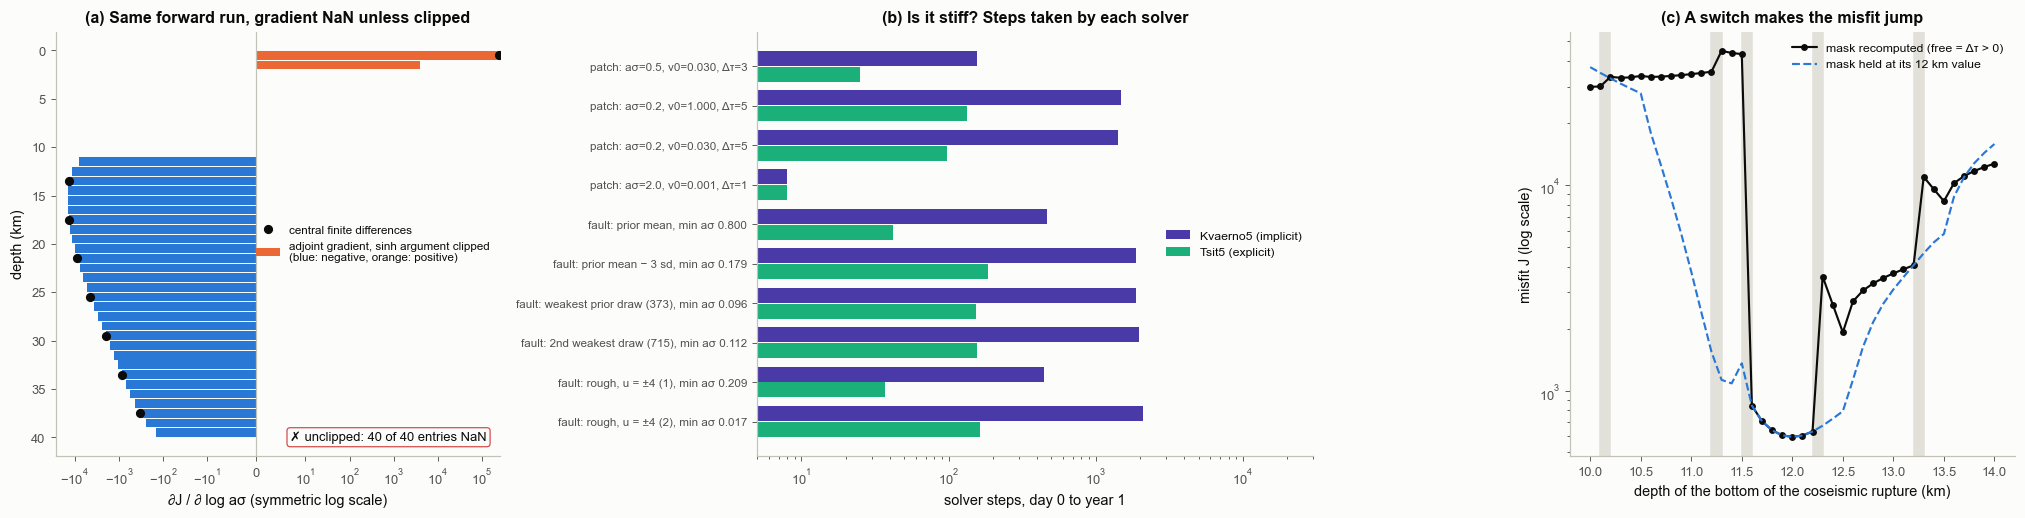

In [16]:
fig, axs = plt.subplots(1, 3, figsize=(18.5, 4.8), gridspec_kw=dict(width_ratios=[1, 1.25, 1]))
ax = axs[0]
if u_bad is not None:
    ax.barh(zc_f, g_bad, height=0.9, color=np.where(g_bad < 0, S.BLUE, S.ORANGE),
            label="adjoint gradient, sinh argument clipped\n(blue: negative, orange: positive)")
    ax.plot(fd_bad, zc_f[fd_idx], "o", color=S.INK, ms=5, label="central finite differences")
    ax.axvline(0, color=S.AXIS, lw=0.8)
    ax.set_xscale("symlog", linthresh=10)
    ax.invert_yaxis()
    n_nan = int(np.sum(~np.isfinite(NANS[("Kvaerno5", False)])))
    S.badge(ax, f"unclipped: {n_nan} of {NP} entries NaN", ok=False, loc="lower right")
    ax.legend(fontsize=7.6, loc="center right")
ax.set_xlabel("∂J / ∂ log aσ (symmetric log scale)"); ax.set_ylabel("depth (km)")
ax.set_title("(a) Same forward run, gradient NaN unless clipped")
ax = axs[1]
labels = [r[0] for r in rows]
y_ = np.arange(len(rows))
ax.barh(y_ - 0.2, [r[1]["Kvaerno5 (implicit)"][0] for r in rows], height=0.38, color=S.VIOLET, label="Kvaerno5 (implicit)")
ax.barh(y_ + 0.2, [r[1]["Tsit5 (explicit)"][0] for r in rows], height=0.38, color=S.AQUA, label="Tsit5 (explicit)")
ax.set_yticks(y_); ax.set_yticklabels(labels, fontsize=7.6)
ax.invert_yaxis(); ax.set_xscale("log"); ax.set_xlim(5, 3e4)
ax.set_xlabel("solver steps, day 0 to year 1")
ax.set_title("(b) Is it stiff? Steps taken by each solver")
ax.legend(fontsize=8, loc="center right")
ax = axs[2]
ax.plot(rbs, L_switch, "o-", color=S.INK, ms=3.5, lw=1.4, label="mask recomputed (free = Δτ > 0)")
ax.plot(rbs, L_fixed, "--", color=S.BLUE, lw=1.4, label="mask held at its 12 km value")
for j in jumps:
    ax.axvspan(rbs[j], rbs[j + 1], color=S.GRID, zorder=0)
ax.set_yscale("log")
ax.set_xlabel("depth of the bottom of the coseismic rupture (km)"); ax.set_ylabel("misfit J (log scale)")
ax.set_title("(c) A switch makes the misfit jump")
ax.legend(fontsize=8)
fig.tight_layout()
bk.savefig(fig, "2-22_pitfalls")
plt.show()

**How to read it.** (a) At the profile where the unclipped search met its first NaN, the clipped gradient is finite
and matches finite differences (dots), while the unclipped one is NaN in every entry (printed, for both solvers),
although the two forward runs are identical. A NaN gradient with a healthy forward run points to a discarded branch,
not to the physics.

(b) Read the printed table with the bars. In every case tried, the explicit `Tsit5` takes no more steps than the
implicit `Kvaerno5`, usually about a tenth as many, runs much faster, and agrees with it to a small fraction of the
2 mm noise; the fault's
sensitivity kernel agrees too (printed). The printed linearised rates show why this is surprising: right after the
earthquake the fastest rate is orders of magnitude above the slowest, the textbook definition of stiffness. But the
fast rates exist only while the stress is high, and they decay as fast as the stress relaxes, so an explicit solver
with adaptive steps is not held back for long. The lesson is not "always use Tsit5"; it is that stiffness is a
property to measure on your own problem and parameter range, because the solver choice multiplies the cost of every
forward run and every gradient. (For this toolkit it is a finding: `bayeskit.afterslip` uses `Kvaerno5`.)

(c) Grey bands mark where a patch switches between pinned and free. With the mask recomputed (black), the misfit
jumps there; with the mask frozen (blue dashed), it is continuous. A gradient-based optimiser or NUTS sees only the
continuous pieces, so the jump acts like an invisible wall. Both curves also have sharp corners where the rupture
bottom passes a patch centre (10.5, 11.5, 12.5, 13.5 km): there the coseismic slip shape $\sin^{0.7}$ of the module
starts with an infinite slope, a second, milder non-smoothness (continuous, not differentiable). Notebook 2.17 §6 shows
the same failures for rounding and other non-smooth operations.

**Other ways it goes wrong** (not computed here): `if` branches on parameter values, table lookups, `max`/`abs` at
their kinks, iteration counts that depend on the parameters (notebook 2.17 §6); finite differences through a code that
writes its results with few digits; and adjoints of discretisations that are not dual consistent (section 3).

## 7. Summary

| route to the gradient | cost per gradient | memory | exact for | watch out for |
|---|---|---|---|---|
| finite differences | $N_m + 1$ (forward) or $2N_m$ (central) forward runs | one forward run | nothing (step-size error; solver error sets the floor) | cost with many parameters; noisy forward codes |
| forward mode (tangent-linear) | about $N_m$ tangent solves | small | the discretised code | many parameters |
| reverse mode, discretise-then-differentiate (autodiff, checkpointing) | about 1 forward + 1 backward, any $N_m$ | stores (or recomputes) the forward steps | the discretised code (dual consistent by construction) | memory for long runs; non-smooth code |
| continuous adjoint (hand-derived or `BacksolveAdjoint`) | about 1 forward + 1 backward, any $N_m$ | small (does not store the forward steps) | the continuous equations (only approximately the code's misfit) | inconsistency with the misfit; derivation effort |

Three ways to use such a forward model in an inversion, by what they cost and return: EnKI needs no derivative and
moves an ensemble with updates built from means and covariances, at $J$ forward runs per step (2.24); the adjoint
plus L-BFGS gives the MAP point at one forward and one adjoint run per step; the adjoint plus HMC/NUTS samples the
posterior at one forward plus one adjoint run per leapfrog step (2.18).

**In practice.**
* When the forward model is a matrix of precomputed Green's functions, each gradient is one product with
  $\mathbf G^\top$ (section 1), so autodiff through it costs about as much as a forward run.
* When the forward model is an ODE or PDE solve per parameter set (stress-driven afterslip, for instance), ensemble
  methods need no gradients. Sections 4-5 show what a gradient costs once the solver is written in a differentiable
  framework: about one extra backward solve per gradient, for any number of parameters. That is not automatically an
  upgrade over an ensemble method: the exact gradient scales to many parameters, but an optimiser then finds a
  *local* minimum, and the uncertainty needs more work (a sampler, or a Laplace approximation, 2.08).
* When making a solver differentiable, check section 6a first (a NaN gradient with a healthy forward run), and time an
  explicit against an implicit solver on your own problem before committing (6b): neither result transfers to
  another solver or parameter range without measuring.
* If a mask or switch depends on the parameters (the pinned patches of section 6c), the misfit is not differentiable
  where it switches; keep such choices fixed during a gradient-based run or treat them as separate models.

Next: [**2.23 · The Kalman filter: inversion through time**](2-23_kalman_filter.ipynb).

In [17]:
print(f"notebook run time: {time.time() - T0:.0f} s")

notebook run time: 176 s
